## 1. Аналіз предметної області

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

In [2]:
df = pd.read_csv('../data/heart_disease_uci.csv')
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [4]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [5]:
df['num'].value_counts().sort_index()

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

In [6]:
df.isna().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [7]:
print('chol = 0:', (df['chol'] == 0).sum())
print('trestbps = 0:', (df['trestbps'] == 0).sum())
print('oldpeak < 0:', (df['oldpeak'] < 0).sum())
print('Дублікати:', df.drop(columns='id').duplicated().sum())

chol = 0: 172
trestbps = 0: 1
oldpeak < 0: 12
Дублікати: 2


In [8]:
pd.concat([
    df.groupby('dataset')['num'].apply(lambda s: (s > 0).mean()).rename('частка хворих'),
    df[['ca', 'thal', 'slope']].isna().groupby(df['dataset']).mean(),
    (df['chol'] == 0).groupby(df['dataset']).mean().rename('chol = 0'),
], axis=1).round(2)

,частка хворих,ca,thal,slope,chol = 0
dataset,,,,,
Cleveland,0.46,0.02,0.01,0.00,0.00
Hungary,0.36,0.99,0.90,0.65,0.00
Switzerland,0.93,0.96,0.42,0.14,1.00
VA Long Beach,0.74,0.99,0.83,0.51,0.24


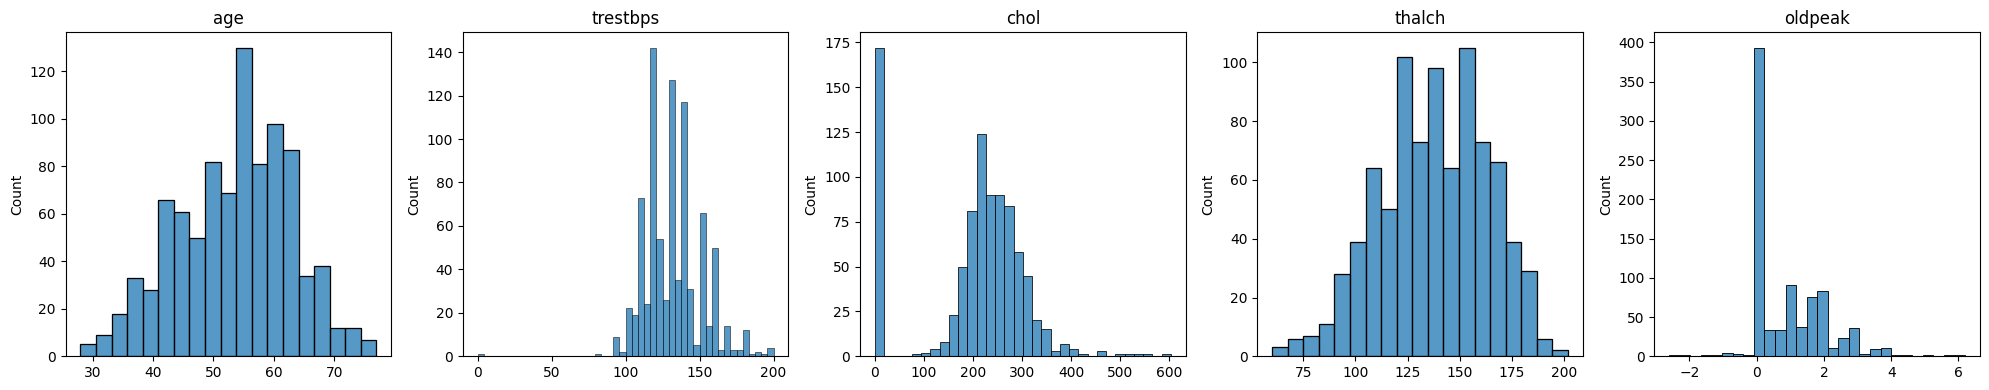

In [9]:
numeric = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, feature in zip(axes, numeric):
    sns.histplot(df[feature], ax=ax)
    ax.set_title(feature)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

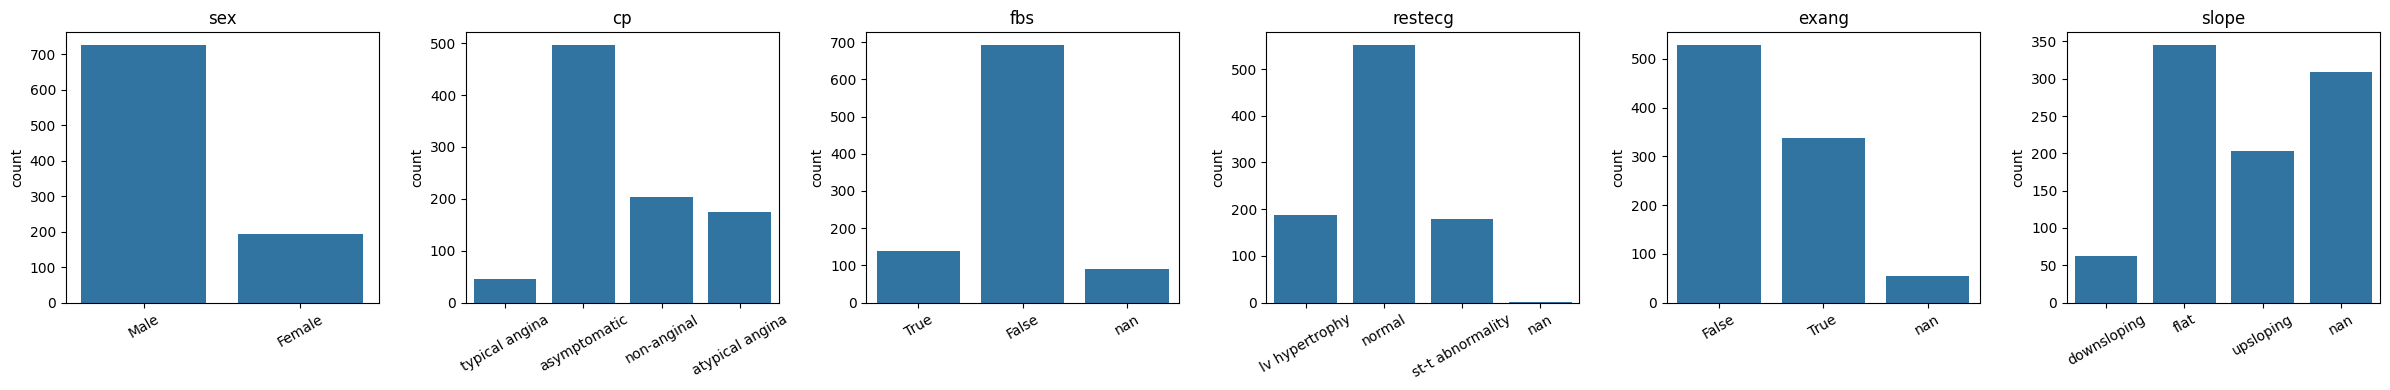

In [10]:
categorical = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope']

fig, axes = plt.subplots(1, 6, figsize=(24, 4))
for ax, feature in zip(axes, categorical):
    sns.countplot(x=df[feature].astype(str), ax=ax)
    ax.set_title(feature)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

## 2. Підготовка даних

In [11]:
data = df.drop_duplicates(subset=df.columns.drop('id')).copy()
data[['chol', 'trestbps']] = data[['chol', 'trestbps']].replace(0, np.nan)
data[['fbs', 'exang']] = data[['fbs', 'exang']].astype(float)

X = data.drop(columns=['id', 'dataset', 'ca', 'thal', 'num'])
y = (data['num'] > 0).astype(int)
print(X.shape)
y.value_counts()

(918, 11)


num
1    508
0    410
Name: count, dtype: int64

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(734, 11) (184, 11)


In [13]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

scaled = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), numeric),
    ('cat', categorical_pipeline, categorical),
])

unscaled = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric),
    ('cat', categorical_pipeline, categorical),
])

## 3. Розробка та тестування моделей

In [14]:
models = {
    'Logistic Regression': Pipeline([('prep', scaled), ('model', LogisticRegression(max_iter=1000))]),
    'SVM': Pipeline([('prep', scaled), ('model', SVC(probability=True, random_state=42))]),
    'Random Forest': Pipeline([('prep', unscaled), ('model', RandomForestClassifier(random_state=42))]),
}

for name, model in models.items():
    model.fit(X_train, y_train)

## 4. Аналіз та порівняння результатів

In [15]:
results = {}
matrices = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    matrices[name] = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = matrices[name].ravel()
    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC-ROC': roc_auc_score(y_test, y_proba),
        'FN': fn,
        'FP': fp,
    }

results = pd.DataFrame(results).T
results[['FN', 'FP']] = results[['FN', 'FP']].astype(int)
results.round(4)

,Accuracy,Precision,Recall,F1,AUC-ROC,FN,FP
Logistic Regression,0.7935,0.8019,0.8333,0.8173,0.8900,17,21
SVM,0.8424,0.8230,0.9118,0.8651,0.8925,9,20
Random Forest,0.7935,0.8019,0.8333,0.8173,0.8860,17,21


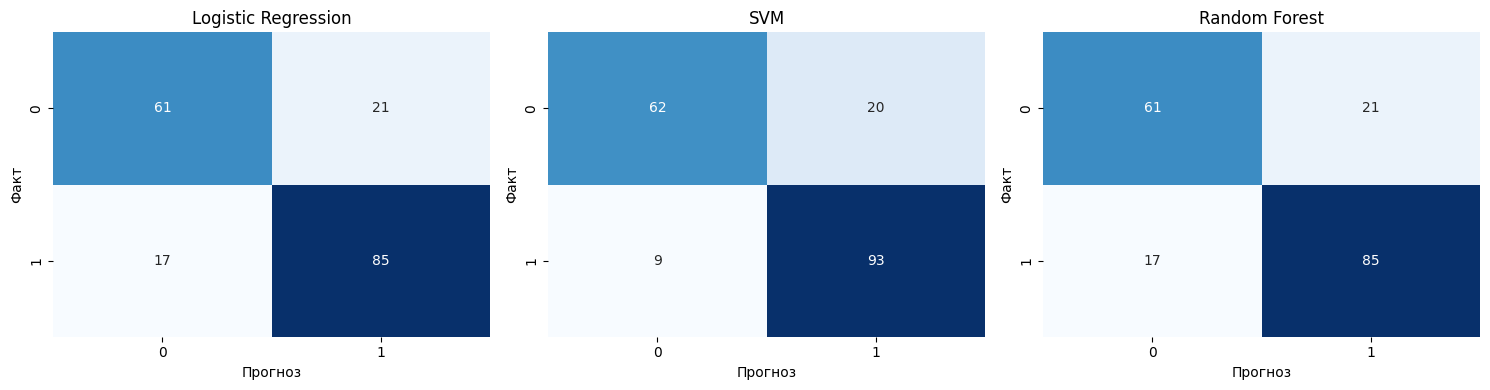

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, matrix) in zip(axes, matrices.items()):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Прогноз')
    ax.set_ylabel('Факт')
plt.tight_layout()
plt.show()

## 5. Практична реалізація

In [17]:
best_name = results.sort_values(['Recall', 'F1', 'AUC-ROC'], ascending=False).index[0]
best_name

'SVM'

In [18]:
joblib.dump(models[best_name], '../models/heart_model.joblib')

['../models/heart_model.joblib']